# Recording：从空间 View 到结果 Schema

本教程只讨论一件事：如何从 Cell population 的空间范围中选择状态或机制，并把它们记录成带静态元数据的结果。一个最小 NetStim network 只负责产生真实事件和突触响应；Synapse 放置、Connection 配对与 Network 组装的完整说明分别见 [synapse.ipynb](../synapse/synapse.ipynb)、[connection.ipynb](../network/connection.ipynb) 和 [network.ipynb](../network/network.ipynb)。

In [1]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import braincell
from braincell import mech
from braincell.filter import BranchSlice, at

brainstate.environ.set(precision=64)

## 1. 先确定两层选择

`record()` 的调用对象决定空间 scope，`observe.*` 再决定该空间内记录什么：

```text
population members -> branch / region -> CV -> mechanism selector -> field
```

| 机制 category | `type` | `name` | 额外身份 | 最小结果行 |
| --- | --- | --- | --- | --- |
| Channel | 动力学模型，例如 `Na_HH1952` | 用户声明的逻辑 owner，例如 `nav` | - | `(cell, CV, channel owner)` |
| Ion | 实现模型，例如 `SodiumFixed` | 逻辑 owner，例如 `na_pool` | `species="na"` | `(cell, CV, ion owner)` |
| Synapse | 动力学模型，例如 `ExpSyn` | 逻辑分组，例如 `fast_ampa` | stable logical `ids` | 一个独立 Synapse 实例 |

`type` 回答“使用哪套方程”，`name` 回答“用户声明的是哪一组”。同一个 type 可以有多个 name；Synapse 的 stable ID 还能继续定位到单个实例。

## 2. 构建带多个逻辑 owner 的 Cell population

四个 cell 共享一套三分支 morphology 和七个 CV。两个 `IL` owner 使用相同 type、不同 name，并分别覆盖 soma 与 dendrite，这使 type/name 的区别可以直接观察。

In [2]:
soma = braincell.Branch.from_lengths(
    lengths=[20.0] * u.um, radii=[10.0, 10.0] * u.um, type="soma",
)
dend_a = braincell.Branch.from_lengths(
    lengths=[120.0] * u.um, radii=[2.0, 1.0] * u.um, type="dendrite",
)
dend_b = braincell.Branch.from_lengths(
    lengths=[160.0] * u.um, radii=[2.5, 0.8] * u.um, type="dendrite",
)
morphology = braincell.Morphology.from_root(soma, name="soma")
morphology.soma.dend_a = dend_a
morphology.soma.dend_b = dend_b

cell = braincell.Cell(
    morphology, cv_policy=braincell.CVPerBranchList((1, 3, 3)),
    pop_size=(4,), solver="staggered", V_init=-65.0 * u.mV, name="post",
)
whole = BranchSlice([0, 1, 2], 0.0, 1.0)
soma_region = BranchSlice([0], 0.0, 1.0)
dendrite_region = BranchSlice([1, 2], 0.0, 1.0)

cell.paint(whole, mech.Ion("SodiumFixed", name="na_pool", E=50.0 * u.mV))
cell.paint(whole, mech.Ion("PotassiumFixed", name="k_pool", E=-77.0 * u.mV))
cell.paint(whole, mech.Channel("Na_HH1952", name="nav", g_max=120.0 * u.mS / u.cm**2))
cell.paint(whole, mech.Channel("K_HH1952", name="kv", g_max=36.0 * u.mS / u.cm**2))
cell.paint(soma_region, mech.Channel("IL", name="leak_soma", g_max=0.3 * u.mS / u.cm**2, E=-54.387 * u.mV))
cell.paint(dendrite_region, mech.Channel("IL", name="leak_dend", g_max=0.3 * u.mS / u.cm**2, E=-54.387 * u.mV))

assert cell.n_cv == 7

### Channel 与 Ion View

空间 View 可以逐层收窄，机制 View 不复制 runtime 数据，只保存所选逻辑行。Channel 支持 `by_type()` 和 `by_name()`/`[name]`；Ion 还支持 `by_species()`。`get()`/`set()` 要求最终只剩一个 `(type, name)` owner，避免把含义不同的参数列混在一起。

In [3]:
cell.channels['leak_soma'].get('E')

Quantity([-54.387 -54.387 -54.387 -54.387], "mV")

In [4]:
spatial_view = cell[[0, 2]].dendrite.cv[1:]
il_by_type = cell.channels.by_type("IL")
soma_leak_by_name = cell.channels["leak_soma"]
sodium_by_species = cell.ions.by_species("na")
sodium_by_type = cell.ions.by_type("SodiumFixed")
sodium_by_name = cell.ions["na_pool"]

display(pd.DataFrame([
    ("cell[[0, 2]].dendrite.cv[1:]", len(spatial_view), "population + branch type + CV"),
    ("cell.channels", len(cell.channels), "all Channel logical rows"),
    ("channels.by_type('IL')", len(il_by_type), f"names={il_by_type.names}"),
    ("channels['leak_soma']", len(soma_leak_by_name), f"types={soma_leak_by_name.types}"),
    ("ions.by_species('na')", len(sodium_by_species), f"names={sodium_by_species.names}"),
    ("ions.by_type('SodiumFixed')", len(sodium_by_type), f"names={sodium_by_type.names}"),
    ("ions['na_pool']", len(sodium_by_name), f"species={tuple(dict.fromkeys(sodium_by_name.species))}"),
], columns=["selection", "rows", "meaning"]))

assert set(il_by_type.names) == {"leak_soma", "leak_dend"}
assert sodium_by_species.names == sodium_by_type.names == sodium_by_name.names == ("na_pool",)

,selection,rows,meaning
0,"cell[[0, 2]].dendrite.cv[1:]",2,population + branch type + CV
1,cell.channels,84,all Channel logical rows
2,channels.by_type('IL'),28,"names=('leak_soma', 'leak_dend')"
3,channels['leak_soma'],4,"types=('IL',)"
4,ions.by_species('na'),28,"names=('na_pool',)"
5,ions.by_type('SodiumFixed'),28,"names=('na_pool',)"
6,ions['na_pool'],28,"species=('na',)"


## 3. Synapse View 的 type、name 与 stable IDs

每个 cell 在同一 dendrite CV 上放置 `fast_ampa` 和 `slow_ampa`，两组都使用 `ExpSyn`；另在另一条 dendrite 上放置一个 `Exp2Syn`。因此 type selector 可以跨两个 name 聚合，而 name 和 IDs 可以继续缩小到一个逻辑组或若干独立实例。

In [5]:
fast_ampa = mech.Synapse("ExpSyn", name="fast_ampa", tau=1.5 * u.ms, e=0.0 * u.mV)
slow_ampa = mech.Synapse("ExpSyn", name="slow_ampa", tau=4.0 * u.ms, e=0.0 * u.mV)
gaba = mech.Synapse("Exp2Syn", name="gaba", tau1=0.5 * u.ms, tau2=6.0 * u.ms, e=-75.0 * u.mV)

cell.place(at("dend_a", 0.35), fast_ampa)
cell.place(at("dend_a", 0.35), slow_ampa)
cell.place(at("dend_b", 0.70), gaba)

exp_synapses = cell.synapses.by_type("ExpSyn")
fast_synapses = cell.synapses["fast_ampa"]
selected_synapses = fast_synapses[[0, 2]]
display(pd.DataFrame([
    ("cell.synapses", len(cell.synapses), tuple(dict.fromkeys(cell.synapses.synapse_type)), tuple(dict.fromkeys(cell.synapses.name))),
    ("synapses.by_type('ExpSyn')", len(exp_synapses), tuple(dict.fromkeys(exp_synapses.synapse_type)), tuple(dict.fromkeys(exp_synapses.name))),
    ("synapses['fast_ampa']", len(fast_synapses), tuple(dict.fromkeys(fast_synapses.synapse_type)), tuple(dict.fromkeys(fast_synapses.name))),
    ("fast_synapses[[0, 2]]", len(selected_synapses), tuple(dict.fromkeys(selected_synapses.synapse_type)), tuple(dict.fromkeys(selected_synapses.name))),
], columns=["selection", "rows", "types", "names"]))
print("selected stable IDs:", selected_synapses.id)

assert len(cell.synapses) == 12
assert len(exp_synapses) == 8
assert len(fast_synapses) == 4
assert len(selected_synapses) == 2

,selection,rows,types,names
0,cell.synapses,12,"(ExpSyn, Exp2Syn)","(fast_ampa, slow_ampa, gaba)"
1,synapses.by_type('ExpSyn'),8,"(ExpSyn,)","(fast_ampa, slow_ampa)"
2,synapses['fast_ampa'],4,"(ExpSyn,)","(fast_ampa,)"
3,"fast_synapses[[0, 2]]",2,"(ExpSyn,)","(fast_ampa,)"


selected stable IDs: [0 2]


## 4. Observable 与输出行

| 请求 | selector | `reduce="none"` 或 state 的行 | 默认 `reduce="sum"` |
| --- | --- | --- | --- |
| Cell state | `observe.state("V")` | 每个所选 `(cell, CV)` 一行 | 不适用 |
| Channel | `channel(type=...)` 或 `channel(name=...)` | 每个 `(cell, CV, owner)` 一行 | 同一 `(cell, CV)` 的命中 channel 求和 |
| Ion | `ion(species/type/name=...)` | 每个 `(cell, CV, owner)` 一行 | 同一 `(cell, CV)` 的命中 ion 求和 |
| Synapse | `synapse(type/name/ids=...)` | 每个 stable Synapse ID 一行 | 同一 `(cell, CV)` 的命中 Synapse 求和 |
| Membrane current | `observe.membrane_current()` | 每个所选 `(cell, CV)` 的总膜电流密度 | 已经是总和 |

膜电位写 `"V"`，与 `cell.V` 同名，结果行的 field 也是 `"V"`；`cell.record(name, "V")` 是 `observe.state("V")` 的简写。其他 state 名（包括 0.3 移除的 `"v"`）在声明时报 `KeyError`。State 不执行 reduction。`current()` 默认求和；需要区分每个贡献者时显式使用 `current(reduce="none")`。selector 参数彼此互斥，例如不能同时传 `type=` 和 `name=`。

In [6]:
cell[[0, 2]].dendrite.cv[1:].record(
    "dend_v", braincell.observe.state("V"), period=0.1 * u.ms,
)
cell.soma.record(
    "nav_p", braincell.observe.channel(name="nav").state("p"), frequency=10.0 * u.kHz,
)
cell.soma.record(
    "sodium_current", braincell.observe.ion(species="na").current(), period=0.1 * u.ms,
)
cell.soma.record(
    "channel_current_rows", braincell.observe.channel().current(reduce="none"), period=0.1 * u.ms,
)
cell.soma.record(
    "channel_current_sum", braincell.observe.channel().current(), period=0.1 * u.ms,
)
cell.record("exp_g", braincell.observe.synapse(type="ExpSyn").state("g"), period=0.1 * u.ms)
cell.record("fast_g", braincell.observe.synapse(name="fast_ampa").state("g"), period=0.1 * u.ms)
cell.record("selected_g", braincell.observe.synapse(ids=selected_synapses.id).state("g"), period=0.1 * u.ms)
cell.record(
    "exp_current_rows", braincell.observe.synapse(type="ExpSyn").current(reduce="none"), period=0.1 * u.ms,
)
cell.record(
    "exp_current_sum", braincell.observe.synapse(type="ExpSyn").current(), period=0.1 * u.ms,
)
cell.soma.record(
    "membrane_current", braincell.observe.membrane_current(), period=0.1 * u.ms, start=0.5 * u.ms,
)

pd.DataFrame({
    "recording": tuple(cell.recordings),
    "period/frequency/start": [
        "period=0.1 ms", "frequency=10 kHz", "period=0.1 ms",
        "period=0.1 ms", "period=0.1 ms", "period=0.1 ms",
        "period=0.1 ms", "period=0.1 ms", "period=0.1 ms",
        "period=0.1 ms", "period=0.1 ms, start=0.5 ms",
    ],
})

,recording,period/frequency/start
0,dend_v,period=0.1 ms
1,nav_p,frequency=10 kHz
2,sodium_current,period=0.1 ms
3,channel_current_rows,period=0.1 ms
4,channel_current_sum,period=0.1 ms
5,exp_g,period=0.1 ms
6,fast_g,period=0.1 ms
7,selected_g,period=0.1 ms
8,exp_current_rows,period=0.1 ms
9,exp_current_sum,period=0.1 ms


记录声明不创建 point mechanism，也不改变 Cell layout。`period` 与 `frequency` 互斥；都省略时每个 `dt` 采样。实际 `period` 和 `start` 在首次运行、已知 `dt` 后验证，必须与 `dt` 的整数步对齐。所有 recording 必须在初始化前声明。

## 5. 最小 Network 驱动

一个 NetStim source 广播到三组 Synapse。这里的 Connection 只用于产生可观察信号，不引入 pairing 或网络级 Synapse 快捷创建。

In [7]:
stim = braincell.NetStim(size=1, start=1.0 * u.ms, number=4, interval=2.0 * u.ms, noise=0.0)
network = braincell.Network("recording_demo", seed=7)
stim_pop = network.add_population("stim", stim)
post_pop = network.add_population("post", cell)

network.connect("drive_fast", source=stim_pop, synapse=post_pop.synapses["fast_ampa"], weight=0.05 * u.uS)
network.connect("drive_slow", source=stim_pop, synapse=post_pop.synapses["slow_ampa"], weight=0.03 * u.uS)
network.connect("drive_gaba", source=stim_pop, synapse=post_pop.synapses["gaba"], weight=0.02 * u.uS)

assert repr(network) == "Network(name='recording_demo', populations=2, connections=3, rows=12)"
print(network)

Network(name='recording_demo', populations=2, connections=3, rows=12)
  populations:
    stim: size=1, kind=netstim, model=NetStim, initialized=False
    post: size=4, kind=cell, model=Cell, initialized=False
  connections:
    post: connections=3, rows=12
      drive_fast: NetStim(stim) -> ExpSyn(fast_ampa), rows=4
      drive_slow: NetStim(stim) -> ExpSyn(slow_ampa), rows=4
      drive_gaba: NetStim(stim) -> Exp2Syn(gaba), rows=4


In [8]:
DT = 0.025 * u.ms
first = network.run(dt=DT, duration=5.0 * u.ms)
second = network.run(dt=DT, duration=5.0 * u.ms)
result = braincell.NetworkResult.concat((first, second))

samples = result.samples["post"]
events = result.events["stim"]["spike"]
assert samples["channel_current_rows"].schema.size == 12
assert samples["channel_current_sum"].schema.size == 4
assert samples["exp_g"].schema.size == 8
assert samples["selected_g"].schema.size == 2
assert samples["exp_current_rows"].schema.size == 8
assert samples["exp_current_sum"].schema.size == 4
assert len(events.time) == 4
assert np.isclose(samples["membrane_current"].time[0].to_decimal(u.ms), 0.5)

pd.DataFrame({
    "recording": list(samples),
    "samples": [block.values.shape[0] for block in samples.values()],
    "rows": [block.schema.size for block in samples.values()],
    "unit": [str(block.schema.rows[0].unit) for block in samples.values()],
})

,recording,samples,rows,unit
0,dend_v,100,10,mV
1,nav_p,100,4,None
2,sodium_current,100,4,mS * mV / cm^2
3,channel_current_rows,100,12,mS * mV / cm^2
4,channel_current_sum,100,4,mS * mV / cm^2
5,exp_g,100,8,uS
6,fast_g,100,4,uS
7,selected_g,100,2,uS
8,exp_current_rows,100,8,nA
9,exp_current_sum,100,4,nA


## 6. SampleBlock、Schema 与稀疏 Events

`result.samples[population][recording]` 返回不可变 `SampleBlock`：`values` 的第一维是采样时间，最后一维严格对应 `schema.rows`。每个 `RecordingRow` 保存空间身份和机制身份，因此结果不依赖列名猜测。求和后的 current 行通过 `contributor_ids` 指向本 recording 中参与归约的原始 contributor 位置。

Source events 不是规则采样矩阵，而是 `result.events[population][port]` 中的稀疏 `EventSeries(time, source_id, count)`。

In [9]:
def schema_frame(block):
    return pd.DataFrame([{
        "population": row.population_index,
        "CV": row.cv_id,
        "branch": row.branch_id,
        "category": row.mechanism_category,
        "type": row.mechanism_type,
        "name": row.mechanism_name,
        "synapse_id": row.synapse_id,
        "field": row.field,
        "contributors": row.contributor_ids,
        "unit": str(row.unit),
    } for row in block.schema.rows])

display("Channel contributors", schema_frame(samples["channel_current_rows"]))
display("Channel current reduced by (cell, CV)", schema_frame(samples["channel_current_sum"]))
display("ExpSyn logical instances", schema_frame(samples["exp_g"]))
display(pd.DataFrame({
    "time (ms)": events.time.to_decimal(u.ms),
    "source_id": events.source_id,
    "count": events.count,
}))

'Channel contributors'

,population,CV,branch,category,type,name,synapse_id,field,contributors,unit
0,0,0,0,channel,Na_HH1952,nav,None,current,(),mS * mV / cm^2
1,0,0,0,channel,K_HH1952,kv,None,current,(),mS * mV / cm^2
2,0,0,0,channel,IL,leak_soma,None,current,(),mS * mV / cm^2
3,1,0,0,channel,Na_HH1952,nav,None,current,(),mS * mV / cm^2
4,1,0,0,channel,K_HH1952,kv,None,current,(),mS * mV / cm^2
5,1,0,0,channel,IL,leak_soma,None,current,(),mS * mV / cm^2
6,2,0,0,channel,Na_HH1952,nav,None,current,(),mS * mV / cm^2
7,2,0,0,channel,K_HH1952,kv,None,current,(),mS * mV / cm^2
8,2,0,0,channel,IL,leak_soma,None,current,(),mS * mV / cm^2
9,3,0,0,channel,Na_HH1952,nav,None,current,(),mS * mV / cm^2


'Channel current reduced by (cell, CV)'

,population,CV,branch,category,type,name,synapse_id,field,contributors,unit
0,0,0,0,None,None,None,None,channel_current,"(0, 1, 2)",mS * mV / cm^2
1,1,0,0,None,None,None,None,channel_current,"(3, 4, 5)",mS * mV / cm^2
2,2,0,0,None,None,None,None,channel_current,"(6, 7, 8)",mS * mV / cm^2
3,3,0,0,None,None,None,None,channel_current,"(9, 10, 11)",mS * mV / cm^2


'ExpSyn logical instances'

,population,CV,branch,category,type,name,synapse_id,field,contributors,unit
0,0,2,1,synapse,ExpSyn,fast_ampa,0,g,(),uS
1,0,2,1,synapse,ExpSyn,slow_ampa,4,g,(),uS
2,1,2,1,synapse,ExpSyn,fast_ampa,1,g,(),uS
3,1,2,1,synapse,ExpSyn,slow_ampa,5,g,(),uS
4,2,2,1,synapse,ExpSyn,fast_ampa,2,g,(),uS
5,2,2,1,synapse,ExpSyn,slow_ampa,6,g,(),uS
6,3,2,1,synapse,ExpSyn,fast_ampa,3,g,(),uS
7,3,2,1,synapse,ExpSyn,slow_ampa,7,g,(),uS


,time (ms),source_id,count
0,1.0,0,1
1,3.0,0,1
2,5.0,0,1
3,7.0,0,1


## 7. Continued run 与不可变结果

连续两次 `run()` 共用全局 recording schedule、Cell state、事件历史和 delay queue。`NetworkResult.concat()` 只接受时间连续、`dt` 相同且 schema 完全一致的片段。`reset_state()` 恢复初始化基线，但不会返回可编辑 topology。

In [10]:
network.reset_state()
continuous = network.run(dt=DT, duration=10.0 * u.ms)

for name, split_block in result.samples["post"].items():
    full_block = continuous.samples["post"][name]
    unit = split_block.schema.rows[0].unit
    split_values = split_block.values if unit is None else split_block.values.to_decimal(unit)
    full_values = full_block.values if unit is None else full_block.values.to_decimal(unit)
    np.testing.assert_allclose(split_values, full_values, rtol=1e-6, atol=1e-7)

np.testing.assert_allclose(
    result.events["stim"]["spike"].time.to_decimal(u.ms),
    continuous.events["stim"]["spike"].time.to_decimal(u.ms),
)
print("split 5 + 5 ms matches reset + continuous 10 ms")

split 5 + 5 ms matches reset + continuous 10 ms


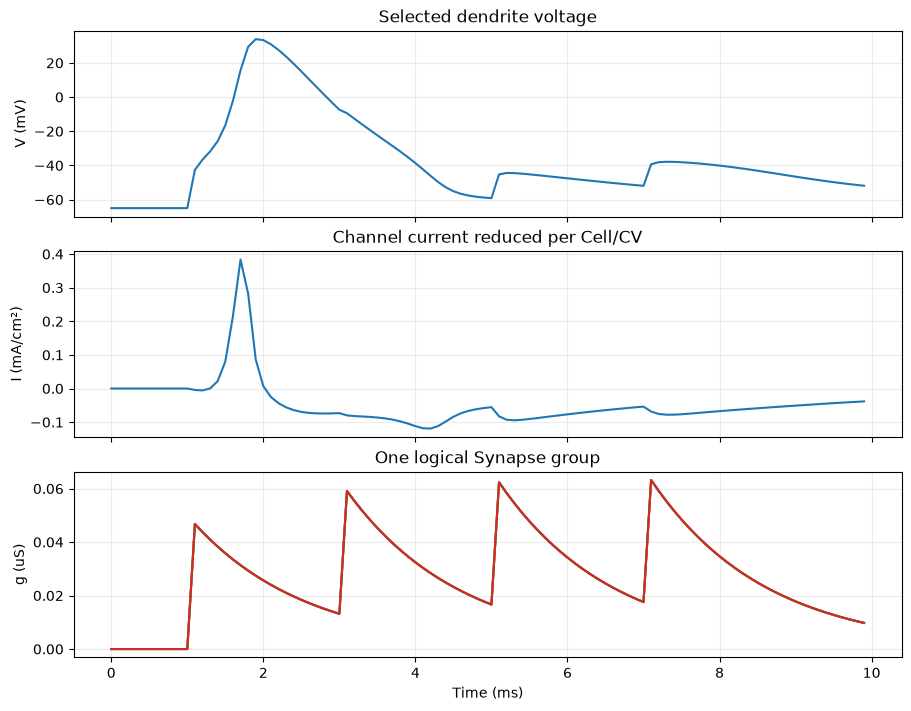

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True, constrained_layout=True)

voltage = samples["dend_v"]
axes[0].plot(voltage.time.to_decimal(u.ms), voltage.values[:, 0].to_decimal(u.mV))
axes[0].set(ylabel="V (mV)", title="Selected dendrite voltage")

channel_current = samples["channel_current_sum"]
axes[1].plot(
    channel_current.time.to_decimal(u.ms),
    channel_current.values[:, 0].to_decimal(u.mA / u.cm**2),
)
axes[1].set(ylabel="I (mA/cm²)", title="Channel current reduced per Cell/CV")

fast_g = samples["fast_g"]
axes[2].plot(fast_g.time.to_decimal(u.ms), fast_g.values.to_decimal(u.uS))
axes[2].set(xlabel="Time (ms)", ylabel="g (uS)", title="One logical Synapse group")
for axis in axes:
    axis.grid(alpha=0.25)
plt.show()

## 8. 单独运行 Cell：`record(name, "V")` 与 `RunResult.spikes`

不进入 Network 时，`Cell.run()` 返回 `RunResult`。`RunResult.spikes` 是 Cell `"spike"` 端口的稀疏 `EventSeries`，格式与同一个 Cell 放进 Network 后的 `result.events[population]["spike"]` 相同：

- 端口读取根分支中点所在 CV 的 `cell.spike`；`metadata["cv_id"]` 给出每一行的 CV。
- 从 `t_k` 到 `t_k + dt` 的一步若使电压从 `V_th` 以下升到 `V_th` 或以上，就在 `t_k` 记一个事件，`count` 为 1；电压停在阈值以上不再产生事件。
- `source_id` 是 population 成员；有 batch 维时按 `(batch,) + pop_size` 的 C 顺序展开，`metadata["batch_index"]` 与 `metadata["population_index"]` 给出每一行的 batch 与成员。
- 在 `jax.jit` 或 `jax.grad` 中运行时事件数取决于数据，`spikes` 为 `None`。

`RunResult` 与 `NetworkResult` 都是 JAX pytree，`jax.block_until_ready(result)` 会等待其中的数组。

In [12]:
def hh_population(amplitudes):
    """Three point HH cells, each driven by its own clamp amplitude."""
    hh = braincell.Cell.point(3, length=20.0 * u.um, radius=10.0 * u.um, V_init=-65.0 * u.mV, solver="rk4")
    hh.paint(
        mech.Ion("SodiumFixed", E=50.0 * u.mV),
        mech.Ion("PotassiumFixed", E=-77.0 * u.mV),
        mech.Channel("Na_HH1952", name="na", g_max=120.0 * u.mS / u.cm**2),
        mech.Channel("K_HH1952", name="k", g_max=36.0 * u.mS / u.cm**2),
        mech.Channel("IL", name="leak", g_max=0.3 * u.mS / u.cm**2, E=-54.3 * u.mV),
    )
    hh.place(at("soma", 0.5), mech.CurrentClamp(delay=1.0 * u.ms, durations=18.0 * u.ms, amplitudes=amplitudes))
    return hh


amplitudes = [0.0, 0.1, 0.2] * u.nA
hh = hh_population(amplitudes)
hh.record("V", "V")
standalone = hh.run(dt=DT, duration=20.0 * u.ms)
spikes = standalone.spikes

# The same Cell in a Network reports the same events.
spiking_network = braincell.Network("spikes_demo")
spiking_network.add_population("hh", hh_population(amplitudes))
in_network = spiking_network.run(dt=DT, duration=20.0 * u.ms).events["hh"]["spike"]
np.testing.assert_array_equal(spikes.source_id, in_network.source_id)
np.testing.assert_allclose(spikes.time.to_decimal(u.ms), in_network.time.to_decimal(u.ms))
assert spikes.metadata["port"] == "spike"

pd.DataFrame({
    "time (ms)": spikes.time.to_decimal(u.ms),
    "source_id": spikes.source_id,
    "count": spikes.count,
    "cv_id": spikes.metadata["cv_id"][spikes.source_id],
})

,time (ms),source_id,count,cv_id
0,2.425,2,1,0
1,3.175,1,1,0
2,15.325,2,1,0
3,19.425,1,1,0


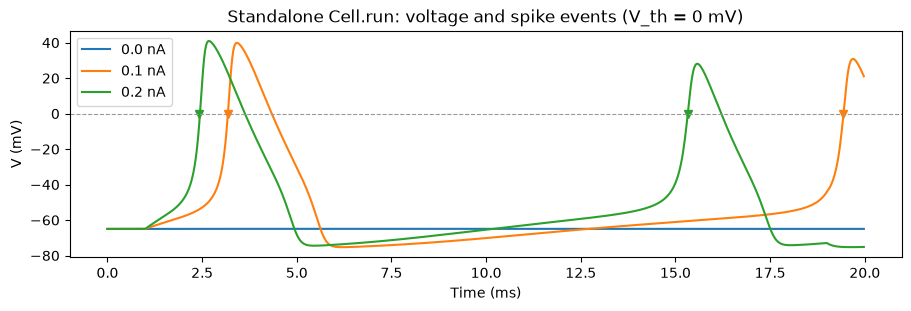

In [13]:
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
v = standalone.samples["V"]
for member, amplitude in enumerate(amplitudes.to_decimal(u.nA)):
    line, = ax.plot(v.time.to_decimal(u.ms), v.values[:, member].to_decimal(u.mV), label=f"{amplitude} nA")
    member_times = spikes.time[spikes.source_id == member].to_decimal(u.ms)
    ax.plot(member_times, np.zeros_like(member_times), "v", color=line.get_color())
ax.axhline(0.0, color="0.6", lw=0.8, ls="--")
ax.set(xlabel="Time (ms)", ylabel="V (mV)", title="Standalone Cell.run: voltage and spike events (V_th = 0 mV)")
ax.legend()
plt.show()

## 小结

空间 View 决定在哪里记录，observable selector 决定记录哪个机制 owner 或 Synapse 实例，field 决定读取什么。规则采样进入带 schema 的 `SampleBlock`，source events 进入稀疏 `EventSeries`；两者都由 NetworkResult 按 population name 组织。单独运行的 Cell 把规则采样放进 `RunResult.samples`，把自己的 spike 放进同样格式的 `RunResult.spikes`。